# Emotion Detection on News

### Description of the data used, extraced from [Zenodo](https://zenodo.org/records/7976208):

This dataset contains news headlines relevant to key forex pairs: AUDUSD, EURCHF, EURUSD, GBPUSD, and USDJPY. The data was extracted from reputable platforms Forex Live and FXstreet over a period of 86 days, from January to May 2023.

The dataset comprises 2,291 unique news headlines. Each headline includes an associated forex pair, timestamp, source, author, URL, and the corresponding article text.

Data was collected using web scraping techniques executed via a custom service on a virtual machine. This service periodically retrieves the latest news for a specified forex pair (ticker) from each platform, parsing all available information. The collected data is then processed to extract details such as the article's timestamp, author, and URL. The URL is further used to retrieve the full text of each article.



```
# This is formatted as code
```

## Data cleaning and preprocessing

### Prompting Google Drive for access


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Importing libraries


In [3]:
import pandas as pd
import spacy
import matplotlib.pyplot as plt
from textblob import TextBlob

### Loading data

In [4]:
news_df = pd.read_csv('/content/drive/MyDrive/HLT project/Project files/sentiment_annotated_with_texts.csv')
news_df.head()

,published_at,ticker,true_sentiment,title,author,url,source,text,finbert_sentiment,finbert_sent_score
0,2023-01-12 07:47:00,EURCHF,Positive,Euro to benefit from the ECBs pronounced hawki...,FXStreet Insights Team,https://www.fxstreet.com/news/euro-to-benefit-...,FX Street,The Euro was able to appreciate particularly s...,Positive,0.85
1,2023-01-12 10:34:00,EURCHF,Positive,EURCHF Trend higher may remain in place – ING,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-trend-hi...,FX Street,EUR/CHF yesterday broke above 1.00. Economists...,Positive,0.51
2,2023-01-12 11:40:00,EURCHF,Neutral,Does a jump in EURCHF point to a break above 1...,FXStreet Insights Team,https://www.fxstreet.com/news/does-a-jump-in-e...,FX Street,EUR/CHF vaults parity for the first time since...,Neutral,0.37
3,2023-01-12 15:32:00,EURCHF,Positive,EURCHF could extend its advance back to levels...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-could-ex...,FX Street,EUR/CHF climbs back above parity. Economists a...,Positive,0.64
4,2023-01-13 11:37:00,EURCHF,Positive,EURCHF to head higher towards 10130 and projec...,FXStreet Insights Team,https://www.fxstreet.com/news/eur-chf-to-head-...,FX Street,EUR/CHF has broken out above the sideways rang...,Positive,0.83


### Data cleaning

In [ ]:
news_df.fillna('', inplace=True)

In [ ]:
# Stemming, removing url?
# more

### Statistics

In [ ]:
num_unique_titles = len(news_df['title'].unique())

num_unique_sources = len(news_df['source'].unique())

num_unique_authors = len(news_df['author'].unique())

print("Number of unique titles:", num_unique_titles)
print("Number of unique sources:", num_unique_sources)
print("Number of unique authors:", num_unique_authors)
print("All of them:", len(news_df))

NameError: name 'news_df' is not defined

## Text classification using SpaCy

In [ ]:
nlp = spacy.load("en_core_web_sm")

def classify_text(text):
    doc = nlp(text)
    return "headline" if len(doc) <= 10 else "news_text"

text_columns = ['title', 'text']

for column in text_columns:
    news_df[column + '_Text_Type'] = news_df[column].apply(classify_text)

### Feature extraction from text

In [ ]:
news_df['TitleLength'] = news_df['title'].apply(len)
news_df['TextLength'] = news_df['text'].apply(len)

print("Title Lengths:", news_df['TitleLength'])
print("Text Lengths:", news_df['TextLength'])

Title Lengths: 0       76
1       45
2       67
3       73
4       74
        ..
2286    74
2287    51
2288    55
2289    82
2290    55
Name: TitleLength, Length: 2291, dtype: int64
Text Lengths: 0        724
1        617
2        779
3        807
4        571
        ... 
2286    1841
2287     566
2288     500
2289     557
2290    1105
Name: TextLength, Length: 2291, dtype: int64


In [ ]:
def tokenize_and_lemmatize(text):
    doc = nlp(text)
    return [token.lemma_ for token in doc]

news_df['TitleTokens'] = news_df['title'].apply(tokenize_and_lemmatize)
news_df['TextTokens'] = news_df['text'].apply(tokenize_and_lemmatize)

print("Title Tokens:", news_df['TitleTokens'])
print("Text Tokens:"), news_df['TextTokens']

Title Tokens: 0       [euro, to, benefit, from, the, ecb, pronounce,...
1       [EURCHF, Trend, higher, may, remain, in, place...
2       [do, a, jump, in, EURCHF, point, to, a, break,...
3       [EURCHF, could, extend, its, advance, back, to...
4       [eurchf, to, head, higher, towards, 10130, and...
                              ...                        
2286    [GBPUSD, hold, steady, near, its, high, level,...
2287    [EURCHF, to, break, below, the, 097, level, –,...
2288    [EURUSD, Shortterm, dip, likely, support, near...
2289    [GBPUSD, look, for, an, eventual, final, leg, ...
2290    [USDJPY, break, below, 13400, as, Wall, Street...
Name: TitleTokens, Length: 2291, dtype: object
Text Tokens:


(None,
 0       [the, Euro, be, able, to, appreciate, particul...
 1       [EUR, /, CHF, yesterday, break, above, 1.00, ....
 2       [EUR, /, CHF, vault, parity, for, the, first, ...
 3       [EUR, /, CHF, climb, back, above, parity, ., e...
 4       [EUR, /, CHF, have, break, out, above, the, si...
                               ...                        
 2286    [the, GBP, /, usd, pair, enter, a, bullish, co...
 2287    [EUR, /, CHF, have, turn, back, lower, over, t...
 2288    [the, European, Central, Bank, (, ecb)downshif...
 2289    [economist, at, Credit, Suisse, discuss, GBP, ...
 2290    [the, USD, /, JPY, have, break, low, and, tumb...
 Name: TextTokens, Length: 2291, dtype: object)

### Sentiment and Emotional Analysis

In [ ]:
def load_lexicon(filepath):
    lexicon = {}
    with open(filepath, 'r') as file:
        for line in file:
            word, valence, arousal, dominance = line.strip().split('\t')
            lexicon[word.lower()] = {'valence': float(valence), 'arousal': float(arousal), 'dominance': float(dominance)}
    return lexicon

lexicon = load_lexicon('/content/drive/MyDrive/NRC-VAD-Lexicon.txt')

In [ ]:
def analyze_emotion(text, dimension):
    scores = [lexicon.get(word.lower(), {}).get(dimension, 0) for word in text.split()]
    return sum(scores) / max(len(scores), 1)

def analyze_valence(text):
    return analyze_emotion(text, 'valence')

def analyze_arousal(text):
    return analyze_emotion(text, 'arousal')

def analyze_dominance(text):
    return analyze_emotion(text, 'dominance')

news_df['TitleValence'] = news_df['title'].apply(analyze_valence)
news_df['TextValence'] = news_df['text'].apply(analyze_valence)

news_df['TitleArousal'] = news_df['title'].apply(analyze_arousal)
news_df['TextArousal'] = news_df['text'].apply(analyze_arousal)

news_df['TitleDominance'] = news_df['title'].apply(analyze_dominance)
news_df['TextDominance'] = news_df['text'].apply(analyze_dominance)

print(news_df[['title', 'text', 'TitleValence', 'TextValence', 'TitleArousal', 'TextArousal', 'TitleDominance', 'TextDominance']].head())

                                               title  \
0  Euro to benefit from the ECBs pronounced hawki...   
1      EURCHF Trend higher may remain in place – ING   
2  Does a jump in EURCHF point to a break above 1...   
3  EURCHF could extend its advance back to levels...   
4  EURCHF to head higher towards 10130 and projec...   

                                                text  TitleValence  \
0  The Euro was able to appreciate particularly s...      0.275636   
1  EUR/CHF yesterday broke above 1.00. Economists...      0.386333   
2  EUR/CHF vaults parity for the first time since...      0.115000   
3  EUR/CHF climbs back above parity. Economists a...      0.125500   
4  EUR/CHF has broken out above the sideways rang...      0.116333   

   TextValence  TitleArousal  TextArousal  TitleDominance  TextDominance  
0     0.170312      0.194455     0.107670        0.256000       0.149661  
1     0.213640      0.209444     0.142532        0.310333       0.178378  
2     0.147459   

In [ ]:
def analyze_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity

news_df['TitleSentiment'] = news_df['title'].apply(analyze_sentiment)
news_df['TextSentiment'] = news_df['text'].apply(analyze_sentiment)

print(news_df[['title', 'text', 'TitleSentiment', 'TextSentiment']].head())

                                               title  \
0  Euro to benefit from the ECBs pronounced hawki...   
1      EURCHF Trend higher may remain in place – ING   
2  Does a jump in EURCHF point to a break above 1...   
3  EURCHF could extend its advance back to levels...   
4  EURCHF to head higher towards 10130 and projec...   

                                                text  TitleSentiment  \
0  The Euro was able to appreciate particularly s...            0.00   
1  EUR/CHF yesterday broke above 1.00. Economists...            0.25   
2  EUR/CHF vaults parity for the first time since...            0.00   
3  EUR/CHF climbs back above parity. Economists a...            0.00   
4  EUR/CHF has broken out above the sideways rang...            0.25   

   TextSentiment  
0       0.257738  
1       0.016667  
2       0.036786  
3       0.195641  
4       0.033333  


### Visualizing

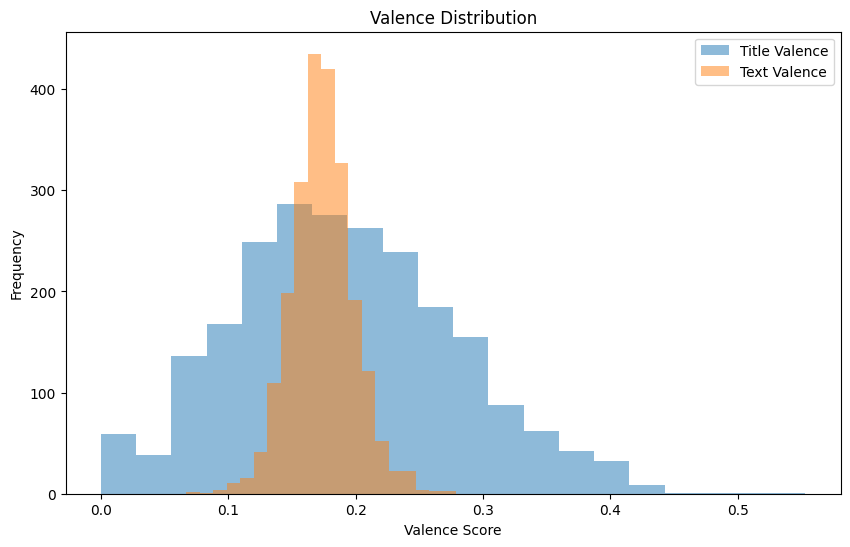

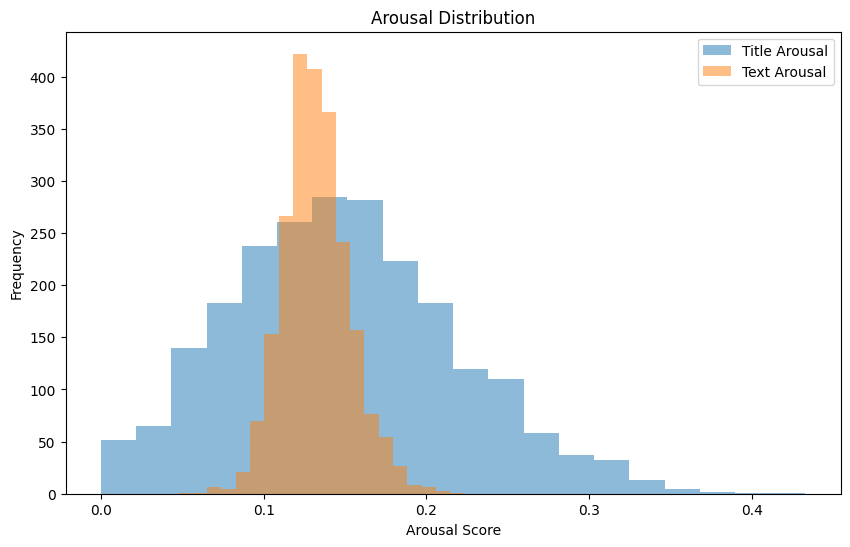

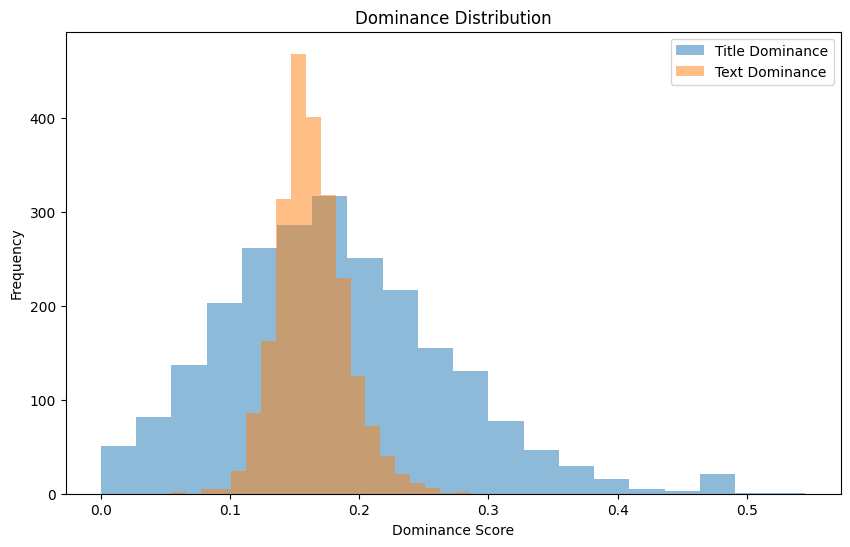

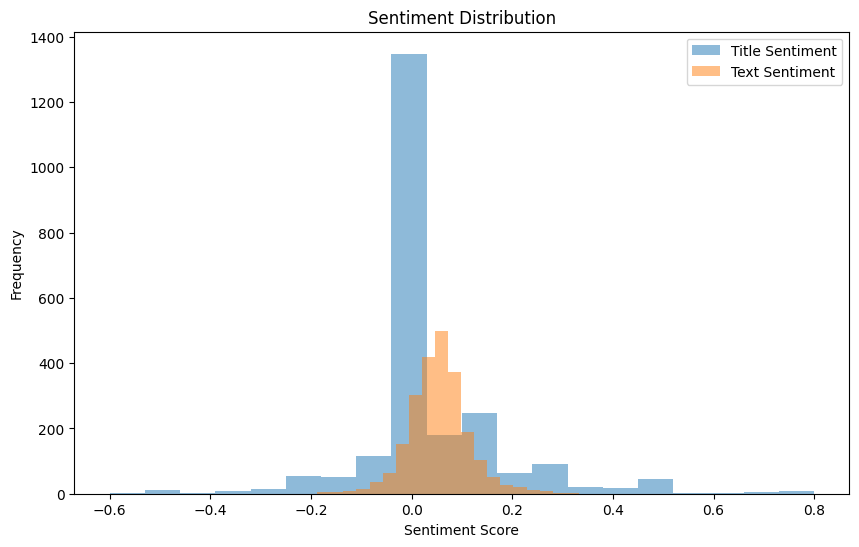

In [ ]:
# Plotting Valence
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleValence'], bins=20, alpha=0.5, label='Title Valence')
plt.hist(news_df['TextValence'], bins=20, alpha=0.5, label='Text Valence')
plt.title('Valence Distribution')
plt.xlabel('Valence Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Arousal
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleArousal'], bins=20, alpha=0.5, label='Title Arousal')
plt.hist(news_df['TextArousal'], bins=20, alpha=0.5, label='Text Arousal')
plt.title('Arousal Distribution')
plt.xlabel('Arousal Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Dominance
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleDominance'], bins=20, alpha=0.5, label='Title Dominance')
plt.hist(news_df['TextDominance'], bins=20, alpha=0.5, label='Text Dominance')
plt.title('Dominance Distribution')
plt.xlabel('Dominance Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# Plotting Sentiment
plt.figure(figsize=(10, 6))
plt.hist(news_df['TitleSentiment'], bins=20, alpha=0.5, label='Title Sentiment')
plt.hist(news_df['TextSentiment'], bins=20, alpha=0.5, label='Text Sentiment')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()